In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

import pandas as pd
import numpy as np

data = {
    "Age": [22, 25, np.nan, 29, 25, 35, 40, 29],
    "Salary": [25000, 30000, 28000, np.nan, 30000, 50000, 60000, np.nan],
    "City": ["Jaipur", "Ahmedabad", "Jaipur", "Delhi",
             "Ahmedabad", "Delhi", "Jaipur", "Delhi"],
    "Experience": [1, 2, 2, 4, 2, 8, 12, 4],
    "Purchased": ["No", "Yes", "No", "Yes", "Yes", "Yes", "No", "Yes"]
}

df = pd.DataFrame(data)

df.to_csv("sample_dataset.csv", index=False)

print("Dataset created successfully!")
display(df)

Dataset created successfully!


,Age,Salary,City,Experience,Purchased
0,22.0,25000.0,Jaipur,1,No
1,25.0,30000.0,Ahmedabad,2,Yes
2,NaN,28000.0,Jaipur,2,No
3,29.0,NaN,Delhi,4,Yes
4,25.0,30000.0,Ahmedabad,2,Yes
5,35.0,50000.0,Delhi,8,Yes
6,40.0,60000.0,Jaipur,12,No
7,29.0,NaN,Delhi,4,Yes


In [3]:

print("First 5 rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

First 5 rows:


,Age,Salary,City,Experience,Purchased
0,22.0,25000.0,Jaipur,1,No
1,25.0,30000.0,Ahmedabad,2,Yes
2,NaN,28000.0,Jaipur,2,No
3,29.0,NaN,Delhi,4,Yes
4,25.0,30000.0,Ahmedabad,2,Yes



Dataset Shape:
(8, 5)

Column Names:
['Age', 'Salary', 'City', 'Experience', 'Purchased']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Age         7 non-null      float64
 1   Salary      6 non-null      float64
 2   City        8 non-null      str    
 3   Experience  8 non-null      int64  
 4   Purchased   8 non-null      str    
dtypes: float64(2), int64(1), str(2)
memory usage: 452.0 bytes

Statistical Summary:


,Age,Salary,City,Experience,Purchased
count,7.000000,6.000000,8,8.000000,8
unique,NaN,NaN,3,NaN,2
top,NaN,NaN,Jaipur,NaN,Yes
freq,NaN,NaN,3,NaN,5
mean,29.285714,37166.666667,NaN,4.375000,NaN
std,6.290583,14288.690166,NaN,3.777282,NaN
min,22.000000,25000.000000,NaN,1.000000,NaN
25%,25.000000,28500.000000,NaN,2.000000,NaN
50%,29.000000,30000.000000,NaN,3.000000,NaN
75%,32.000000,45000.000000,NaN,5.000000,NaN


In [4]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
Age           1
Salary        2
City          0
Experience    0
Purchased     0
dtype: int64

Total missing values:
3


In [5]:

print("Before cleaning:")
print(df.isnull().sum())

df["Age"] = df["Age"].fillna(df["Age"].median())

df["Salary"] = df["Salary"].fillna(df["Salary"].median())

print("\nAfter cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset:")
display(df)

Before cleaning:
Age           1
Salary        2
City          0
Experience    0
Purchased     0
dtype: int64

After cleaning:
Age           0
Salary        0
City          0
Experience    0
Purchased     0
dtype: int64

Cleaned dataset:


,Age,Salary,City,Experience,Purchased
0,22.0,25000.0,Jaipur,1,No
1,25.0,30000.0,Ahmedabad,2,Yes
2,29.0,28000.0,Jaipur,2,No
3,29.0,30000.0,Delhi,4,Yes
4,25.0,30000.0,Ahmedabad,2,Yes
5,35.0,50000.0,Delhi,8,Yes
6,40.0,60000.0,Jaipur,12,No
7,29.0,30000.0,Delhi,4,Yes


In [6]:

print("Duplicate rows:")
print(df.duplicated().sum())

display(df[df.duplicated()])

Duplicate rows:
2


,Age,Salary,City,Experience,Purchased
4,25.0,30000.0,Ahmedabad,2,Yes
7,29.0,30000.0,Delhi,4,Yes


In [7]:

df = pd.get_dummies(
    df,
    columns=["City"],
    dtype=int
)


df["Purchased"] = df["Purchased"].map({
    "No": 0,
    "Yes": 1
})

print("Dataset after encoding:")
display(df)

print("\nUpdated column names:")
print(df.columns.tolist())

Dataset after encoding:


,Age,Salary,Experience,Purchased,City_Ahmedabad,City_Delhi,City_Jaipur
0,22.0,25000.0,1,0,0,0,1
1,25.0,30000.0,2,1,1,0,0
2,29.0,28000.0,2,0,0,0,1
3,29.0,30000.0,4,1,0,1,0
4,25.0,30000.0,2,1,1,0,0
5,35.0,50000.0,8,1,0,1,0
6,40.0,60000.0,12,0,0,0,1
7,29.0,30000.0,4,1,0,1,0



Updated column names:
['Age', 'Salary', 'Experience', 'Purchased', 'City_Ahmedabad', 'City_Delhi', 'City_Jaipur']


In [8]:

from sklearn.preprocessing import MinMaxScaler

numeric_columns = ["Age", "Salary", "Experience"]

scaler = MinMaxScaler()

df_scaled = df.copy()

df_scaled[numeric_columns] = scaler.fit_transform(
    df_scaled[numeric_columns]
)

print("Dataset after scaling:")
display(df_scaled)

print("\nMinimum values after scaling:")
print(df_scaled[numeric_columns].min())

print("\nMaximum values after scaling:")
print(df_scaled[numeric_columns].max())

Dataset after scaling:


,Age,Salary,Experience,Purchased,City_Ahmedabad,City_Delhi,City_Jaipur
0,0.000000,0.000000,0.000000,0,0,0,1
1,0.166667,0.142857,0.090909,1,1,0,0
2,0.388889,0.085714,0.090909,0,0,0,1
3,0.388889,0.142857,0.272727,1,0,1,0
4,0.166667,0.142857,0.090909,1,1,0,0
5,0.722222,0.714286,0.636364,1,0,1,0
6,1.000000,1.000000,1.000000,0,0,0,1
7,0.388889,0.142857,0.272727,1,0,1,0



Minimum values after scaling:
Age           0.0
Salary        0.0
Experience    0.0
dtype: float64

Maximum values after scaling:
Age           1.0
Salary        1.0
Experience    1.0
dtype: float64


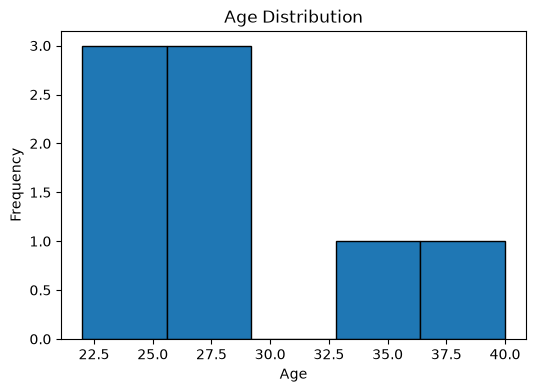

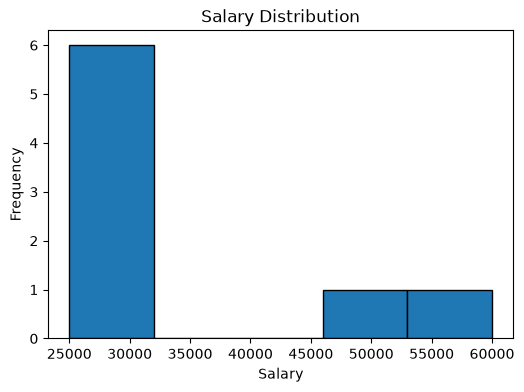

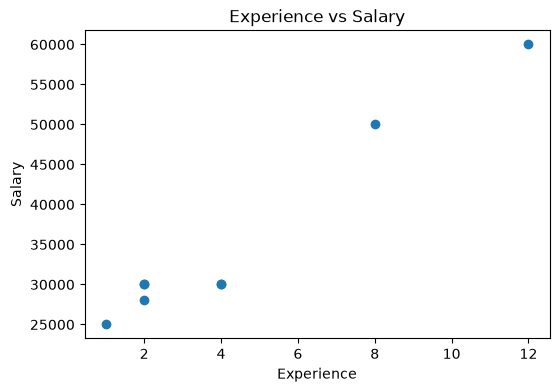

In [9]:

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.hist(df["Age"], bins=5, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(df["Salary"], bins=5, edgecolor="black")
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(df["Experience"], df["Salary"])
plt.title("Experience vs Salary")
plt.xlabel("Experience")
plt.ylabel("Salary")
plt.show()

In [10]:

X = df.drop(columns=["Purchased"])
y = df["Purchased"]

print("Selected Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

print("\nFeature Data Shape:", X.shape)
print("Target Data Shape:", y.shape)

Selected Features:
['Age', 'Salary', 'Experience', 'City_Ahmedabad', 'City_Delhi', 'City_Jaipur']

Target Variable:
Purchased

Feature Data Shape: (8, 6)
Target Data Shape: (8,)


In [11]:

df.to_csv("cleaned_dataset.csv", index=False)
df_scaled.to_csv("scaled_dataset.csv", index=False)

print("Files saved successfully!")
print("1. cleaned_dataset.csv")
print("2. scaled_dataset.csv")

Files saved successfully!
1. cleaned_dataset.csv
2. scaled_dataset.csv
